# P5 — Deteksi Tepi SIMUTEH

Notebook ini mengikuti petunjuk praktikum P5-P6 SIMUTEH.

## Bagian 1 — Gradien dan operator tepi

In [1]:

from pathlib import Path
import json
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd()
if not (root / "src").exists():
    root = root.parent
sys.path.insert(0, str(root / "src"))

from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal



PARAM = json.loads((root / "hasil" / "param_praproses.json").read_text(encoding="utf-8"))
label = pd.read_csv(root / "data" / "sintetis" / "label.csv")
hasil_dir = root / "hasil"
hasil_dir.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 30)

def muat(nama):
    img = baca(str(root / "data" / "sintetis" / "citra" / nama))
    md = cv2.imread(str(root / "data" / "sintetis" / "mask_daun" / nama), 0)
    mb = cv2.imread(str(root / "data" / "sintetis" / "mask_bercak" / nama), 0)
    if md is None or mb is None:
        raise FileNotFoundError(f"Mask tidak lengkap untuk {nama}")
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
print("Root:", root)
print("Jumlah citra:", len(label))


Root: C:\Users\user\Documents\Simuteh-1063
Jumlah citra: 60


### Langkah 1.1 — Lembar hitung manual

In [2]:

A = np.array([[52, 55, 180], [50, 58, 185], [54, 60, 190]], dtype=float)
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)
sobel_y = sobel_x.T
prewitt_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=float)
prewitt_y = prewitt_x.T
laplace = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=float)

def hitung_manual(kx, ky):
    gx, gy = float((A * kx).sum()), float((A * ky).sum())
    return {"Gx": gx, "Gy": gy, "magnitudo": float(np.hypot(gx, gy)),
            "L1": abs(gx) + abs(gy),
            "arah_gradien": float(np.degrees(np.arctan2(gy, gx)))}

manual = pd.DataFrame([hitung_manual(sobel_x, sobel_y),
                       hitung_manual(prewitt_x, prewitt_y)],
                      index=["Sobel", "Prewitt"]).round(3)
manual["Laplacian"] = float((A * laplace).sum())
print(manual)
print("Arah tepi tegak lurus terhadap arah gradien.")


            Gx    Gy  magnitudo     L1  arah_gradien  Laplacian
Sobel    534.0  22.0    534.453  556.0         2.359      118.0
Prewitt  399.0  17.0    399.362  416.0         2.440      118.0
Arah tepi tegak lurus terhadap arah gradien.


### Langkah 1.2 — Gradien Sobel manual dan verifikasi OpenCV

Selisih maksimum Gx manual vs cv2.Sobel: 0.0


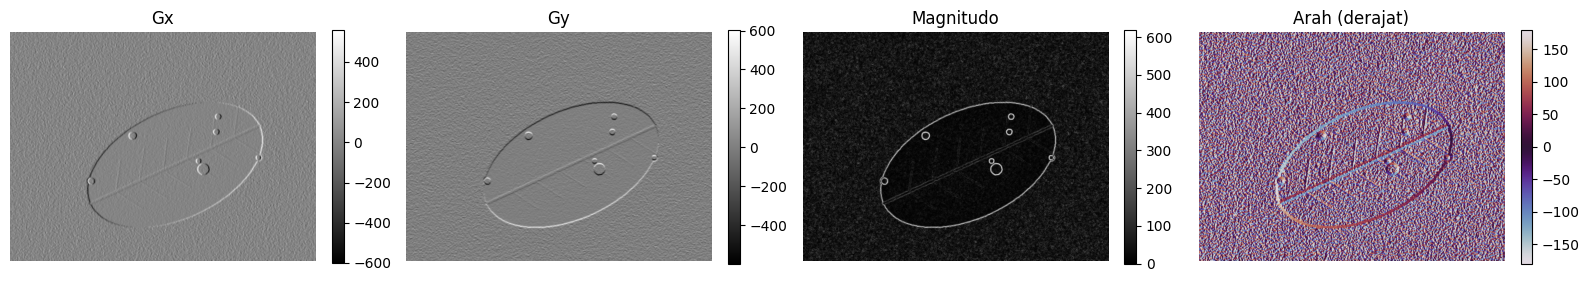

In [3]:

g = pra[:, :, 2].astype(np.float32)
gx = cv2.filter2D(g, cv2.CV_32F, sobel_x.astype(np.float32))
gy = cv2.filter2D(g, cv2.CV_32F, sobel_y.astype(np.float32))
mag = np.hypot(gx, gy)
arah = np.degrees(np.arctan2(gy, gx))
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("Selisih maksimum Gx manual vs cv2.Sobel:", float(np.abs(gx - gx_cv).max()))
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, c, judul in zip(ax, [gx, gy, mag, arah], ["Gx", "Gy", "Magnitudo", "Arah (derajat)"]):
    im = a.imshow(c, cmap="twilight" if judul.startswith("Arah") else "gray")
    a.set_title(judul); a.axis("off"); fig.colorbar(im, ax=a, fraction=0.035)
plt.tight_layout()
plt.show()


### Langkah 1.3–1.5 — Operator dan perbandingan menyeluruh

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.758  0.750  0.753
                LoG      0.598  0.995  0.737
                Prewitt  0.780  0.973  0.858
                Sobel    0.743  0.976  0.833
          R     Canny    0.980  0.974  0.975
                LoG      0.877  0.995  0.919
                Prewitt  0.529  0.994  0.639
                Sobel    0.468  0.995  0.578
praproses Gray  Canny    0.667  0.945  0.776
                LoG      0.519  0.995  0.669
                Prewitt  0.525  0.995  0.677
                Sobel    0.492  0.995  0.644
          R     Canny    0.956  0.986  0.970
                LoG      0.812  0.996  0.878
                Prewitt  0.417  0.996  0.554
                Sobel    0.371  0.996  0.507


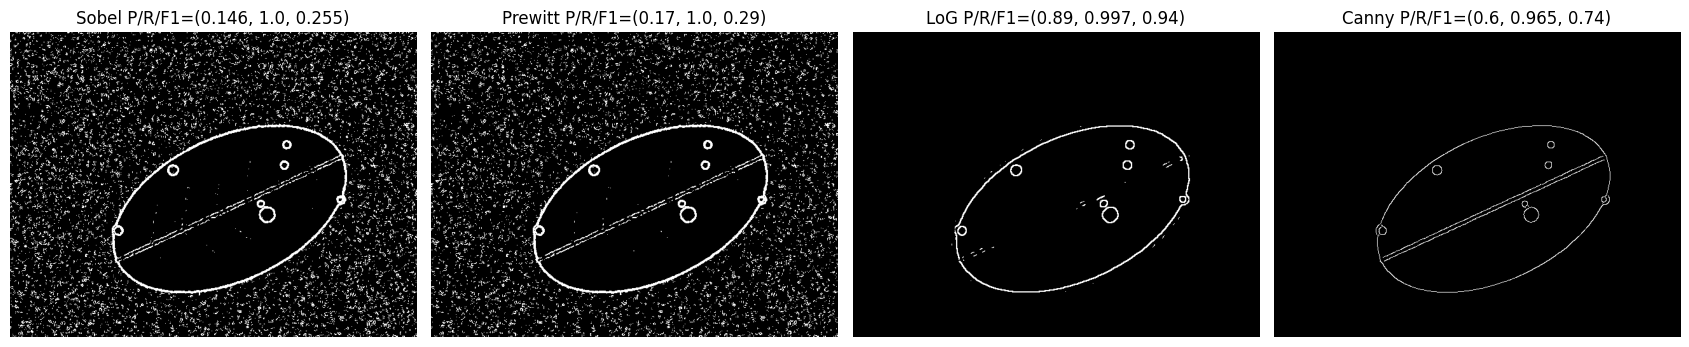

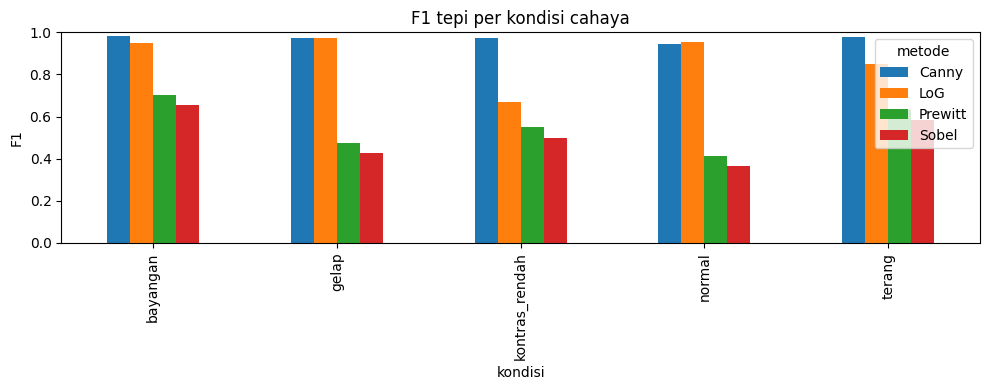

In [4]:

def tepi_sobel(gray, T=100):
    gray = gray.astype(np.float32)
    m = np.hypot(cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3),
                cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(gray, T=75):
    gray = gray.astype(np.float32)
    gx = cv2.filter2D(gray, cv2.CV_32F, prewitt_x.astype(np.float32))
    gy = cv2.filter2D(gray, cv2.CV_32F, prewitt_y.astype(np.float32))
    return ((np.hypot(gx, gy) > T) * 255).astype(np.uint8)

def tepi_log(gray, sigma=3.0, frac=0.2):
    smooth = cv2.GaussianBlur(gray.astype(np.float32), (0, 0), sigma)
    lap = cv2.Laplacian(smooth, cv2.CV_32F)
    mn = cv2.erode(lap, np.ones((3, 3), np.float32))
    mx = cv2.dilate(lap, np.ones((3, 3), np.float32))
    kuat = mx - mn > frac * max(float(np.abs(lap).max()), 1e-6)
    return (((mn < 0) & (mx > 0) & kuat) * 255).astype(np.uint8)

def tepi_canny(gray, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        gray = cv2.GaussianBlur(gray, (0, 0), sigma)
    return cv2.Canny(gray, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt,
          "LoG": tepi_log, "Canny": tepi_canny}
g = pra[:, :, 2]
panel = {nama: fungsi(g) for nama, fungsi in metode.items()}
tampil(list(panel.values()), [f"{nama} P/R/F1={skor_tepi(e, acuan)}"
                              for nama, e in panel.items()],
       baris=1, ukuran=(17, 3.6))

baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    citra, md_i, mb_i = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md_i), tepi_acuan(mb_i))
    for sumber, im in [("mentah", citra), ("praproses", praproses(citra, PARAM))]:
        for kanal, kanal_img in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)),
                                 ("R", im[:, :, 2])]:
            for nama, fungsi in metode.items():
                p, r, f1 = skor_tepi(fungsi(kanal_img), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nama, p, r, f1])
tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
print(tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3))
tabel_tepi.to_csv(hasil_dir / "p5_tabel_tepi.csv", index=False)
grafik = (tabel_tepi[(tabel_tepi.sumber == "praproses") & (tabel_tepi.kanal == "R")]
          .groupby(["kondisi", "metode"])["F1"].mean().unstack())
grafik.plot.bar(figsize=(10, 4), ylim=(0, 1), ylabel="F1", title="F1 tepi per kondisi cahaya")
plt.tight_layout(); plt.savefig(hasil_dir / "p5_f1_kondisi.png", dpi=150); plt.show()


## Bagian 2 — Canny dan keputusan pemakaian tepi

### Langkah 2.1 — NMS dan hysteresis secara manual

In [5]:
# Empat kasus NMS: arah 0, 45, 90, dan 135 derajat.
def nms_tengah(magnitudo, arah):
    pusat = magnitudo[1, 1]
    if arah in (0, 180):
        tetangga = (magnitudo[1, 0], magnitudo[1, 2])
    elif arah == 90:
        tetangga = (magnitudo[0, 1], magnitudo[2, 1])
    elif arah == 45:
        tetangga = (magnitudo[0, 1], magnitudo[1, 2])
    else:
        tetangga = (magnitudo[0, 1], magnitudo[1, 0])
    return pusat >= max(tetangga)

kasus_nms = {
    "0_derajat": (np.array([[20, 10, 20], [40, 100, 30], [20, 10, 20]]), 0),
    "45_derajat": (np.array([[20, 90, 20], [40, 100, 30], [20, 20, 20]]), 45),
    "90_derajat": (np.array([[20, 40, 20], [10, 100, 10], [20, 30, 20]]), 90),
    "135_derajat": (np.array([[20, 20, 20], [30, 100, 40], [20, 90, 20]]), 135),
}
print("NMS empat arah:", {nama: nms_tengah(m, arah) for nama, (m, arah) in kasus_nms.items()})
nilai = np.array([20, 60, 120, 80, 40, 90, 30])
print("Klasifikasi kuat (>=100):", (nilai >= 100).astype(int).tolist())
print("Klasifikasi lemah (50..99):", ((nilai >= 50) & (nilai < 100)).astype(int).tolist())
print("Tepi akhir terhubung ke tepi kuat:", [0, 1, 1, 1, 0, 0, 0])


NMS empat arah: {'0_derajat': np.True_, '45_derajat': np.True_, '90_derajat': np.True_, '135_derajat': np.True_}
Klasifikasi kuat (>=100): [0, 0, 1, 0, 0, 0, 0]
Klasifikasi lemah (50..99): [0, 1, 0, 1, 0, 1, 0]
Tepi akhir terhubung ke tepi kuat: [0, 1, 1, 1, 0, 0, 0]


### Langkah 2.2–2.3 — Eksperimen ambang dan ambang otomatis

In [6]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    citra, md_i, mb_i = muat(d.nama_file)
    g_i = praproses(citra, PARAM)[:, :, 2]
    ac = cv2.bitwise_or(tepi_acuan(md_i), tepi_acuan(mb_i))
    ab = tepi_acuan(mb_i)
    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:
            e = tepi_canny(g_i, lo, hi, sigma)
            p, r, f1 = skor_tepi(e, ac)
            baris.append([d.kelas, d.kondisi_cahaya, sigma, f"{lo}/{hi}", p, r, f1,
                          skor_tepi(e, ab)[1]])
canny = pd.DataFrame(baris, columns=["kelas", "kondisi", "sigma", "ambang", "P", "R", "F1", "R_bercak"])
print("Tabel 7 - Canny per kondisi:")
print(canny.groupby(["sigma", "ambang", "kondisi"])[["P", "R", "F1", "R_bercak"]].mean().round(3))
canny.to_csv(hasil_dir / "p5_canny_eksperimen.csv", index=False)


Tabel 7 - Canny per kondisi:
                                  P      R     F1  R_bercak
sigma ambang  kondisi                                      
0.0   100/200 bayangan        0.683  0.994  0.766     0.980
              gelap           0.388  0.992  0.496     0.978
              kontras_rendah  0.496  0.988  0.602     0.968
              normal          0.254  0.991  0.377     0.968
              terang          0.530  0.994  0.668     0.980
      30/90   bayangan        0.020  0.997  0.040     0.989
              gelap           0.018  0.996  0.035     0.987
              kontras_rendah  0.021  0.997  0.041     0.993
              normal          0.017  0.997  0.033     0.982
              terang          0.018  0.997  0.036     0.988
      50/150  bayangan        0.129  0.996  0.213     0.985
              gelap           0.042  0.993  0.080     0.980
              kontras_rendah  0.125  0.992  0.178     0.978
              normal          0.028  0.992  0.054     0.971
           

### Langkah 2.4–2.6 — Ambang berbasis persentil dan tepi palsu

In [7]:
def canny_persentil(gray, q, rasio=0.4, sigma=2.0):
    smooth = cv2.GaussianBlur(gray.astype(np.float32), (0, 0), sigma)
    gx = cv2.Sobel(smooth, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(smooth, cv2.CV_32F, 0, 1, ksize=3)
    atas = float(np.percentile(np.hypot(gx, gy), q))
    return cv2.Canny(np.clip(smooth, 0, 255).astype(np.uint8), int(rasio * atas), int(atas))

baris, median_baris = [], []
for _, d in label[label.kelas != "sehat"].iterrows():
    citra, md_i, mb_i = muat(d.nama_file)
    pra_i = praproses(citra, PARAM)
    ac = cv2.bitwise_or(tepi_acuan(md_i), tepi_acuan(mb_i))
    for kanal, gray in [("Gray", cv2.cvtColor(pra_i, cv2.COLOR_BGR2GRAY)), ("R", pra_i[:, :, 2])]:
        median_baris.append([d.kondisi_cahaya, kanal, float(np.median(gray))])
        for q in [90, 95, 98]:
            e = canny_persentil(gray, q)
            p, r, f1 = skor_tepi(e, ac)
            baris.append([d.kondisi_cahaya, d.kelas, kanal, q, p, r, f1])
persentil = pd.DataFrame(baris, columns=["kondisi", "kelas", "kanal", "q", "P", "R", "F1"])
print("F1 Canny persentil per kondisi:")
print(persentil.groupby(["kanal", "q", "kondisi"])["F1"].mean().round(3))
persentil.to_csv(hasil_dir / "p5_canny_persentil.csv", index=False)
median_kanal = pd.DataFrame(median_baris, columns=["kondisi", "kanal", "median"])
print("Median per kanal-kondisi:")
print(median_kanal.pivot_table(index="kondisi", columns="kanal", values="median").round(2))
median_kanal.to_csv(hasil_dir / "p5_median_kanal_kondisi.csv", index=False)

baris = []
for _, d in label[label.kelas == "sehat"].iterrows():
    citra, md_i, _ = muat(d.nama_file)
    pra_i = praproses(citra, PARAM)
    gray = cv2.cvtColor(pra_i, cv2.COLOR_BGR2GRAY)
    tepi = tepi_canny(pra_i[:, :, 2])
    gradien = cv2.morphologyEx(md_i, cv2.MORPH_GRADIENT,
                               np.ones((3, 3), np.uint8),
                               borderType=cv2.BORDER_CONSTANT, borderValue=0)
    dalam = cv2.erode(md_i, np.ones((7, 7), np.uint8), borderType=cv2.BORDER_CONSTANT) > 0
    baris.append([d.kondisi_cahaya, float(np.mean(gradien > 0)), int(((tepi > 0) & dalam).sum()),
                  float(np.median(gray)), float(np.median(pra_i[:, :, 2]))])
gradien_daun = pd.DataFrame(baris, columns=["kondisi", "piksel_gradien_daun", "tepi_internal_R", "median_Gray", "median_R"])
print("Gradien tepi daun dan tepi internal:")
print(gradien_daun.groupby("kondisi").mean(numeric_only=True).round(2))
gradien_daun.to_csv(hasil_dir / "p5_gradien_tepi_daun.csv", index=False)


F1 Canny persentil per kondisi:
kanal  q   kondisi       
Gray   90  bayangan          0.064
           gelap             0.062
           kontras_rendah    0.051
           normal            0.057
           terang            0.053
       95  bayangan          0.300
           gelap             0.304
           kontras_rendah    0.101
           normal            0.258
           terang            0.170
       98  bayangan          0.738
           gelap             0.744
           kontras_rendah    0.697
           normal            0.726
           terang            0.737
R      90  bayangan          0.069
           gelap             0.064
           kontras_rendah    0.052
           normal            0.059
           terang            0.055
       95  bayangan          0.234
           gelap             0.108
           kontras_rendah    0.106
           normal            0.132
           terang            0.126
       98  bayangan          0.960
           gelap             0.9

Gradien tepi daun dan tepi internal:
                piksel_gradien_daun  tepi_internal_R  median_Gray  median_R
kondisi                                                                    
bayangan                       0.01              0.0       111.50    119.75
gelap                          0.01              0.0       136.50    163.00
kontras_rendah                 0.01              0.0       148.75    152.00
normal                         0.01            176.0       171.50    180.75
terang                         0.01            260.5       196.75    198.00


**Keputusan yang perlu didokumentasikan di laporan:** gunakan deteksi tepi untuk memperoleh batas daun atau fitur bentuk bila bukti F1 mendukung; jangan memakai tepi langsung sebagai luas bercak karena tepi tidak mengisi wilayah. Segmentasi wilayah bercak dilanjutkan dengan mask biner dan morfologi pada notebook P6.